In [21]:
from google.colab import drive
drive.mount('/content/drive')
from scipy.stats import ttest_ind
import os
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
import numpy as np
from scipy.stats import norm
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from scipy.stats import gaussian_kde
from patsy import dmatrices
# paths
data_path = '/content/drive/My Drive/data' #carpeta data
output_path = '/content/drive/My Drive/output' #carpeta output



file_name = '202408091215A665F0C336D2A52B__casestudy_dropout.dta'
datos = pd.read_stata(os.path.join(data_path, file_name))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [22]:
datos.head(5)

,IDstudent,IDschool,SchoolGrade2022,DropoutDate,DayOfWeekDroppedOut,PrioritaryStudentIn2021,Female,Age,GPAin2021,AttendanceIn2021,GraduatedIn2021,Migrant,ListedInDropoutReport,SchoolPrincipalADP,EnrolledByAug312022,GraduatedIn2022,MunicipalSchool,SchoolDaysFromMay302022,DroppedOutMay30Before
0,1.0,1,12.0,2022-06-17,5.0,0,0,18,2.0,55,0.0,0.0,0.0,1.0,0.0,0.0,1.0,-14,0.0
1,2.0,1,9.0,2022-05-13,5.0,0,1,15,2.5,55,0.0,0.0,1.0,1.0,1.0,0.0,1.0,11,1.0
2,3.0,1,10.0,2022-04-20,3.0,1,1,14,4.9,88,1.0,0.0,0.0,1.0,0.0,0.0,1.0,28,1.0
3,4.0,4,10.0,2022-05-02,1.0,1,1,14,5.8,90,1.0,0.0,1.0,1.0,0.0,0.0,1.0,20,1.0
4,5.0,4,12.0,2022-06-15,3.0,0,1,17,4.6,100,1.0,0.0,0.0,1.0,0.0,0.0,1.0,-12,0.0


Variables de la base:
--
1.   **IDstudent**: Id único de cada estudiante
2.   **Idschool**: Id único de la escuela
3.   **SchoolGrade2022**: Indica el curso que estaba cursando el estudiante durante el 2022. Toma valores del 1 al 12.
4.   **DropoutDate**: Fecha en la que el estudiante se desvinculó del establecimiento
5.   **DayofWeekDroppedOut**: Día de la semana en que abandonó la escuela, toma valores del 1 al 5
6.   **PrioritaryStudentIn2021**: Binaria que indica 1 si el estudiante era alumno prioritario en el año 2021, 0 si no
7.   **Female**: Binaria que indica 1 si el estudiante es mujer, 0 si no
8.   **Age**: Edad del estudiante
9.   **GPAin2021**: Nota final en 2021
10.  **AttendanceIn2021**: Porcentaje de asistencia del alumno durante 2021
11.  **GraduatedIn2021**: Binaria que indica 1 si el estudiante se graduó en el año 2021, o 0 si no
12.  **Migrant**: Binaria que indica 1 si el estudiante es migrante, 0 si no
13.  **ListedInDropoutReport**: Binaria que indica 1 si el estudiante está en la lista de individuos que aún no se han reincorporado al sistema escolar, 0 si no aparece en esta lista
14.  **SchoolPrincipalADP**:---
15.  **EnrolledByAug312022**: Binaria que indica 1 si el estudiante logro reincoporarse al sistema educativo al 31/08/2021, o si no
16.  **GraduatedIn2022**: Binaria que indica 1 si el estudiante se graduó en el año 2022, o 0 si no
17.  **MunicipalSchool**: Binaria que indica 1 si el establecimiento al que asistia el estudiante era municipal, 0 si no
18.  **SchoolDaysFromMay302022**:---
19.  **DroppedOutMay30Before**:Binaria que indica 1 si el estudiante se desvinculó de la escuela antes del 30 de Mayo.

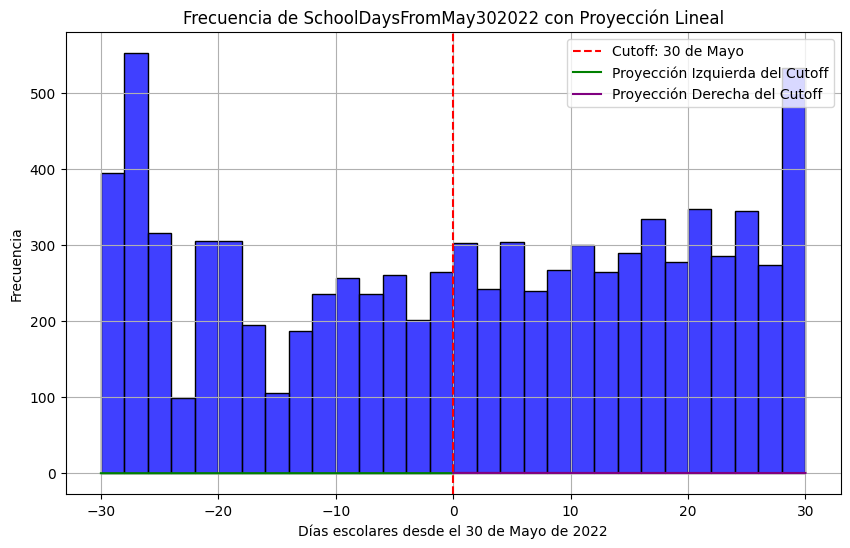

Intercepto izquierda: 0.04468876496607525
Intercepto derecha: 0.3987472850548405
Estadístico z: -24.951384990673496
p-valor: 0.0
Hay una diferencia significativa entre los interceptos a ambos lados del cutoff.


<ipython-input-23-34de881af2da>:49: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  intercept_left = reg_left.params[0]
<ipython-input-23-34de881af2da>:50: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  intercept_right = reg_right.params[0]
<ipython-input-23-34de881af2da>:53: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  std_err_left = reg_left.bse[0]
<ipython-input-23-34de881af2da>:54: FutureWarning: Series.__getitem__ treating keys a

In [23]:
#P1)
# dividiendo datos
left_of_cutoff = datos[datos['SchoolDaysFromMay302022'] < 0]
right_of_cutoff = datos[datos['SchoolDaysFromMay302022'] >= 0]

# variables dependientes x e independientes y a ambos lados
X_left = left_of_cutoff['SchoolDaysFromMay302022']
X_right = right_of_cutoff['SchoolDaysFromMay302022']
y_left = left_of_cutoff['ListedInDropoutReport']
y_right = right_of_cutoff['ListedInDropoutReport']

X_left_const = sm.add_constant(X_left)
X_right_const = sm.add_constant(X_right)

# Ajustando regresiones
reg_left = sm.OLS(y_left, X_left_const).fit()
reg_right = sm.OLS(y_right, X_right_const).fit()


X_range_left = np.linspace(min(datos['SchoolDaysFromMay302022']), 0, 100)
X_range_right = np.linspace(0, max(datos['SchoolDaysFromMay302022']), 100)
pred_left = reg_left.predict(sm.add_constant(X_range_left))
pred_right = reg_right.predict(sm.add_constant(X_range_right))

# hist

plt.figure(figsize=(10, 6))
sns.histplot(datos['SchoolDaysFromMay302022'], bins=30, kde=False, color='blue')

plt.axvline(x=0, color='red', linestyle='--', label="Cutoff: 30 de Mayo")

plt.plot(X_range_left, pred_left, color='green', label="Proyección Izquierda del Cutoff")
plt.plot(X_range_right, pred_right, color='purple', label="Proyección Derecha del Cutoff")

plt.title("Frecuencia de SchoolDaysFromMay302022 con Proyección Lineal")
plt.xlabel("Días escolares desde el 30 de Mayo de 2022")
plt.ylabel("Frecuencia")
plt.legend()
p1_graph_path = os.path.join(output_path, 'Gráfico p1.png')
plt.savefig(p1_graph_path)
plt.grid(True)
p1_graph_path = os.path.join(output_path, 'Gráfico p1.png')
plt.savefig(p1_graph_path)
plt.show()

# Test de hipótesis para interceptos

# interceptos
intercept_left = reg_left.params[0]
intercept_right = reg_right.params[0]

# errores
std_err_left = reg_left.bse[0]
std_err_right = reg_right.bse[0]

# estadistico z
z_stat = (intercept_left - intercept_right) / np.sqrt(std_err_left**2 + std_err_right**2)

# p valor
p_value = 2 * (1 - norm.cdf(abs(z_stat)))  # Test de dos colas

# resultados
print(f"Intercepto izquierda: {intercept_left}")
print(f"Intercepto derecha: {intercept_right}")
print(f"Estadístico z: {z_stat}")
print(f"p-valor: {p_value}")

# print general
if p_value < 0.05:
    print("Hay una diferencia significativa entre los interceptos a ambos lados del cutoff.")
else:
    print("No hay evidencia significativa de diferencia entre los interceptos a ambos lados del cutoff.")


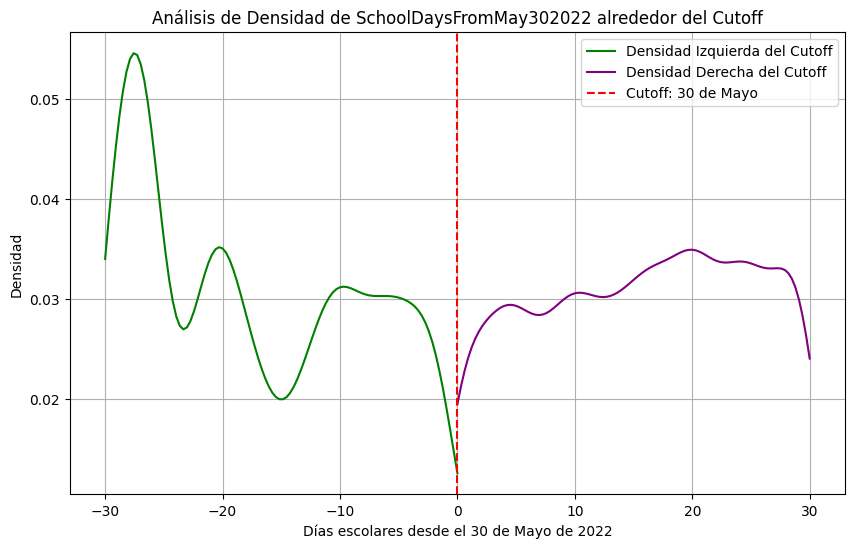

In [24]:
#p1
running_variable = datos['SchoolDaysFromMay302022']

left_side = running_variable[running_variable < 0]
right_side = running_variable[running_variable >= 0]

# densidades
density_left = gaussian_kde(left_side)
density_right = gaussian_kde(right_side)

x_left = np.linspace(min(left_side), 0, 100)
x_right = np.linspace(0, max(right_side), 100)

plt.figure(figsize=(10, 6))

plt.plot(x_left, density_left(x_left), color='green', label="Densidad Izquierda del Cutoff")

plt.plot(x_right, density_right(x_right), color='purple', label="Densidad Derecha del Cutoff")

plt.axvline(x=0, color='red', linestyle='--', label="Cutoff: 30 de Mayo")

plt.title("Análisis de Densidad de SchoolDaysFromMay302022 alrededor del Cutoff")
plt.xlabel("Días escolares desde el 30 de Mayo de 2022")
plt.ylabel("Densidad")
plt.legend()

plt.grid(True)
p1_1_graph_path = os.path.join(output_path, 'Gráfico p1.1.png')
plt.savefig(p1_1_graph_path)
plt.show()


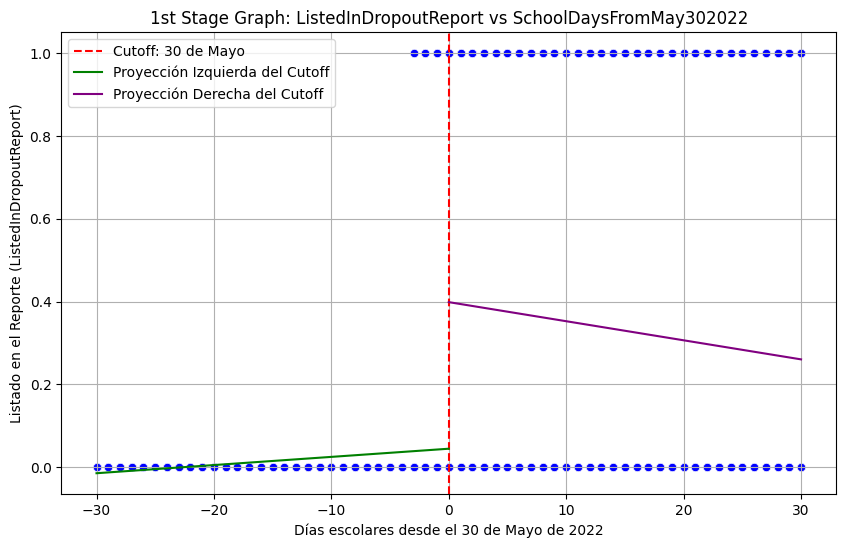

In [25]:
#p2

plt.figure(figsize=(10, 6))

sns.scatterplot(x='SchoolDaysFromMay302022', y='ListedInDropoutReport', data=datos, color='blue')

plt.axvline(x=0, color='red', linestyle='--', label="Cutoff: 30 de Mayo")

left_of_cutoff = datos[datos['SchoolDaysFromMay302022'] < 0]
right_of_cutoff = datos[datos['SchoolDaysFromMay302022'] >= 0]

X_left = left_of_cutoff['SchoolDaysFromMay302022']
X_right = right_of_cutoff['SchoolDaysFromMay302022']
y_left = left_of_cutoff['ListedInDropoutReport']
y_right = right_of_cutoff['ListedInDropoutReport']


X_left_const = sm.add_constant(X_left)
X_right_const = sm.add_constant(X_right)

reg_left = sm.OLS(y_left, X_left_const).fit()
reg_right = sm.OLS(y_right, X_right_const).fit()

X_range_left = np.linspace(min(datos['SchoolDaysFromMay302022']), 0, 100)
X_range_right = np.linspace(0, max(datos['SchoolDaysFromMay302022']), 100)
pred_left = reg_left.predict(sm.add_constant(X_range_left))
pred_right = reg_right.predict(sm.add_constant(X_range_right))


plt.plot(X_range_left, pred_left, color='green', label="Proyección Izquierda del Cutoff")
plt.plot(X_range_right, pred_right, color='purple', label="Proyección Derecha del Cutoff")


plt.title("1st Stage Graph: ListedInDropoutReport vs SchoolDaysFromMay302022")
plt.xlabel("Días escolares desde el 30 de Mayo de 2022")
plt.ylabel("Listado en el Reporte (ListedInDropoutReport)")
plt.legend()

p2_graph_path = os.path.join(output_path, 'Gráfico p2.png')
plt.savefig(p2_graph_path)
plt.grid(True)
plt.show()


In [26]:
#p2.b)
# int
datos = pd.read_stata(os.path.join(data_path, file_name))
datos['Interaction'] = datos['DroppedOutMay30Before'] * datos['SchoolDaysFromMay302022']

formula = 'ListedInDropoutReport ~ DroppedOutMay30Before + SchoolDaysFromMay302022 + Interaction + C(IDschool)'

modelo = smf.ols(formula, data=datos).fit()

coef_interes = ['Intercept', 'DroppedOutMay30Before', 'SchoolDaysFromMay302022', 'Interaction']

tabla_coeficientes = pd.DataFrame({
    'Coeficiente': modelo.params[modelo.params.index.isin(coef_interes)],
    'Error estándar': modelo.bse[modelo.bse.index.isin(coef_interes)],
    't-valor': modelo.tvalues[modelo.tvalues.index.isin(coef_interes)],
    'P-valor': modelo.pvalues[modelo.pvalues.index.isin(coef_interes)]
})


latex_path = os.path.join(output_path, 'tabla_coeficientes_cutoff.tex')
with open(latex_path, 'w') as f:
    f.write(tabla_coeficientes.to_latex(index=True))

print(tabla_coeficientes.to_latex(index=True))

txt_path = os.path.join(output_path, 'tabla_coeficientes_cutoff.txt')
with open(txt_path, 'w') as f:
    f.write(tabla_coeficientes.to_string(index=True))

print(tabla_coeficientes)



\begin{tabular}{lrrrr}
\toprule
 & Coeficiente & Error estándar & t-valor & P-valor \\
\midrule
Intercept & 0.184352 & 0.195455 & 0.943195 & 0.345618 \\
DroppedOutMay30Before & 0.339465 & 0.017883 & 18.982109 & 0.000000 \\
SchoolDaysFromMay302022 & 0.002710 & 0.000697 & 3.888364 & 0.000102 \\
Interaction & -0.007686 & 0.000951 & -8.081533 & 0.000000 \\
\bottomrule
\end{tabular}

                         Coeficiente  Error estándar    t-valor       P-valor
Intercept                   0.184352        0.195455   0.943195  3.456178e-01
DroppedOutMay30Before       0.339465        0.017883  18.982109  3.660798e-78
SchoolDaysFromMay302022     0.002710        0.000697   3.888364  1.019679e-04
Interaction                -0.007686        0.000951  -8.081533  7.615505e-16


<ipython-input-27-2d8d0b281e32>:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='DayOfWeekDroppedOut', data=datos, palette='viridis')
/usr/local/lib/python3.10/dist-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.10/dist-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.10/dist-packages/seaborn/_base.py:949: FutureWarning: When grouping with a 

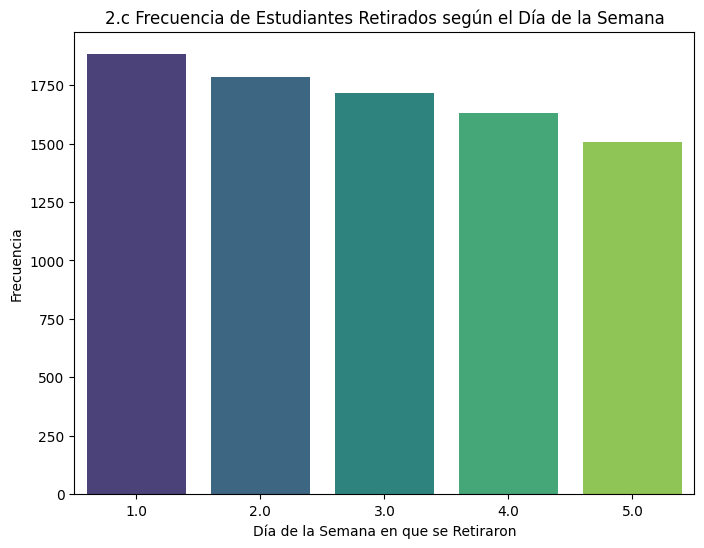

Index(['IDstudent', 'IDschool', 'SchoolGrade2022', 'DropoutDate',
       'PrioritaryStudentIn2021', 'Female', 'Age', 'GPAin2021',
       'AttendanceIn2021', 'GraduatedIn2021', 'Migrant',
       'ListedInDropoutReport', 'SchoolPrincipalADP', 'EnrolledByAug312022',
       'GraduatedIn2022', 'MunicipalSchool', 'SchoolDaysFromMay302022',
       'DroppedOutMay30Before', 'Interaction', 'DayOfWeekDroppedOut_2.0',
       'DayOfWeekDroppedOut_3.0', 'DayOfWeekDroppedOut_4.0',
       'DayOfWeekDroppedOut_5.0'],
      dtype='object')
                         Coeficiente  Error estándar    t-valor       P-valor
Intercept                   0.215427        0.195738   1.100590  2.711176e-01
DroppedOutMay30Before       0.341900        0.017986  19.009159  2.256177e-78
SchoolDaysFromMay302022     0.002576        0.000698   3.689729  2.264021e-04
Interaction                -0.007693        0.000951  -8.088198  7.215081e-16
\begin{tabular}{lrrrr}
\toprule
 & Coeficiente & Error estándar & t-valor & P-valo

In [27]:
#p2.c)
datos = pd.read_stata(os.path.join(data_path, file_name))
datos.columns = datos.columns.str.strip()
datos['Interaction'] = datos['DroppedOutMay30Before'] * datos['SchoolDaysFromMay302022']


plt.figure(figsize=(8, 6))
sns.countplot(x='DayOfWeekDroppedOut', data=datos, palette='viridis')
plt.title('2.c Frecuencia de Estudiantes Retirados según el Día de la Semana')
plt.xlabel('Día de la Semana en que se Retiraron')
plt.ylabel('Frecuencia')

p2c_graph_path = os.path.join(output_path, 'Gráfico p2c.png')
plt.savefig(p2c_graph_path)
plt.show()

# dummies
datos = pd.get_dummies(datos, columns=['DayOfWeekDroppedOut'], drop_first=True)
print(datos.columns)
datos.columns = datos.columns.str.replace('.', '_', regex=False)

# 2.c
formula = 'ListedInDropoutReport ~ DroppedOutMay30Before + SchoolDaysFromMay302022 + Interaction + C(IDschool) + ' + \
          ' + '.join([col for col in datos.columns if col.startswith('DayOfWeekDroppedOut_')])

modelo_2c = smf.ols(formula, data=datos).fit()


coef_interes_2c = ['Intercept', 'DroppedOutMay30Before', 'SchoolDaysFromMay302022', 'Interaction'] + \
                  [col for col in datos.columns if col.startswith('DayOfWeekDroppedOut_')]


tabla_coeficientes_2c = pd.DataFrame({
    'Coeficiente': modelo_2c.params[modelo_2c.params.index.isin(coef_interes_2c)],
    'Error estándar': modelo_2c.bse[modelo_2c.bse.index.isin(coef_interes_2c)],
    't-valor': modelo_2c.tvalues[modelo_2c.tvalues.index.isin(coef_interes_2c)],
    'P-valor': modelo_2c.pvalues[modelo_2c.pvalues.index.isin(coef_interes_2c)]
})


latex_path_2c = os.path.join(output_path, 'tabla_coeficientes_2c.tex')
with open(latex_path_2c, 'w') as f:
    f.write(tabla_coeficientes_2c.to_latex(index=True))


txt_path_2c = os.path.join(output_path, 'tabla_coeficientes_2c.txt')
with open(txt_path_2c, 'w') as f:
    f.write(tabla_coeficientes_2c.to_string(index=True))


print(tabla_coeficientes_2c)

print(tabla_coeficientes_2c.to_latex(index=True))


In [28]:
#p3)
datos = pd.read_stata(os.path.join(data_path, file_name))
dayofweek_dummies = [col for col in datos.columns if col.startswith('DayOfWeekDroppedOut_')]

if dayofweek_dummies:
    dayofweek_dummies_str = ' + ' + ' + '.join(dayofweek_dummies)
else:
    dayofweek_dummies_str = ''

formula_enrollment = f'EnrolledByAug312022 ~ DroppedOutMay30Before + SchoolDaysFromMay302022 + DroppedOutMay30Before:SchoolDaysFromMay302022 + C(IDschool){dayofweek_dummies_str}'

# primer modelo
modelo_enrollment = smf.ols(formula_enrollment, data=datos).fit()

coef_interes_enrollment = ['Intercept', 'DroppedOutMay30Before', 'SchoolDaysFromMay302022', 'DroppedOutMay30Before:SchoolDaysFromMay302022'] + dayofweek_dummies

tabla_coeficientes_enrollment = pd.DataFrame({
    'Coeficiente': modelo_enrollment.params[modelo_enrollment.params.index.isin(coef_interes_enrollment)],
    'Error estándar': modelo_enrollment.bse[modelo_enrollment.bse.index.isin(coef_interes_enrollment)],
    't-valor': modelo_enrollment.tvalues[modelo_enrollment.tvalues.index.isin(coef_interes_enrollment)],
    'P-valor': modelo_enrollment.pvalues[modelo_enrollment.pvalues.index.isin(coef_interes_enrollment)]
})

latex_path_enrollment = os.path.join(output_path, 'tabla_coeficientes_enrollment_3.tex')
with open(latex_path_enrollment, 'w') as f:
    f.write(tabla_coeficientes_enrollment.to_latex(index=True))

txt_path_enrollment = os.path.join(output_path, 'tabla_coeficientes_enrollment_3.txt')
with open(txt_path_enrollment, 'w') as f:
    f.write(tabla_coeficientes_enrollment.to_string(index=True))

print(tabla_coeficientes_enrollment)


print(tabla_coeficientes_enrollment.to_latex(index=True))

# segundo modelo
formula_graduation = f'GraduatedIn2022 ~ DroppedOutMay30Before + SchoolDaysFromMay302022 + DroppedOutMay30Before:SchoolDaysFromMay302022 + C(IDschool){dayofweek_dummies_str}'

modelo_graduation = smf.ols(formula_graduation, data=datos).fit()

coef_interes_graduation = ['Intercept', 'DroppedOutMay30Before', 'SchoolDaysFromMay302022', 'DroppedOutMay30Before:SchoolDaysFromMay302022'] + dayofweek_dummies

tabla_coeficientes_graduation = pd.DataFrame({
    'Coeficiente': modelo_graduation.params[modelo_graduation.params.index.isin(coef_interes_graduation)],
    'Error estándar': modelo_graduation.bse[modelo_graduation.bse.index.isin(coef_interes_graduation)],
    't-valor': modelo_graduation.tvalues[modelo_graduation.tvalues.index.isin(coef_interes_graduation)],
    'P-valor': modelo_graduation.pvalues[modelo_graduation.pvalues.index.isin(coef_interes_graduation)]
})

latex_path_graduation = os.path.join(output_path, 'tabla_coeficientes_graduation_3.tex')
with open(latex_path_graduation, 'w') as f:
    f.write(tabla_coeficientes_graduation.to_latex(index=True))


txt_path_graduation = os.path.join(output_path, 'tabla_coeficientes_graduation_3.txt')
with open(txt_path_graduation, 'w') as f:
    f.write(tabla_coeficientes_graduation.to_string(index=True))


print(tabla_coeficientes_graduation)


print(tabla_coeficientes_graduation.to_latex(index=True))


                                               Coeficiente  Error estándar  \
Intercept                                         0.307276        0.224061   
DroppedOutMay30Before                             0.046694        0.020501   
SchoolDaysFromMay302022                          -0.001602        0.000799   
DroppedOutMay30Before:SchoolDaysFromMay302022     0.000637        0.001090   

                                                t-valor   P-valor  
Intercept                                      1.371393  0.170302  
DroppedOutMay30Before                          2.277698  0.022778  
SchoolDaysFromMay302022                       -2.004613  0.045048  
DroppedOutMay30Before:SchoolDaysFromMay302022  0.583858  0.559337  
\begin{tabular}{lrrrr}
\toprule
 & Coeficiente & Error estándar & t-valor & P-valor \\
\midrule
Intercept & 0.307276 & 0.224061 & 1.371393 & 0.170302 \\
DroppedOutMay30Before & 0.046694 & 0.020501 & 2.277698 & 0.022778 \\
SchoolDaysFromMay302022 & -0.001602 & 0.000799 

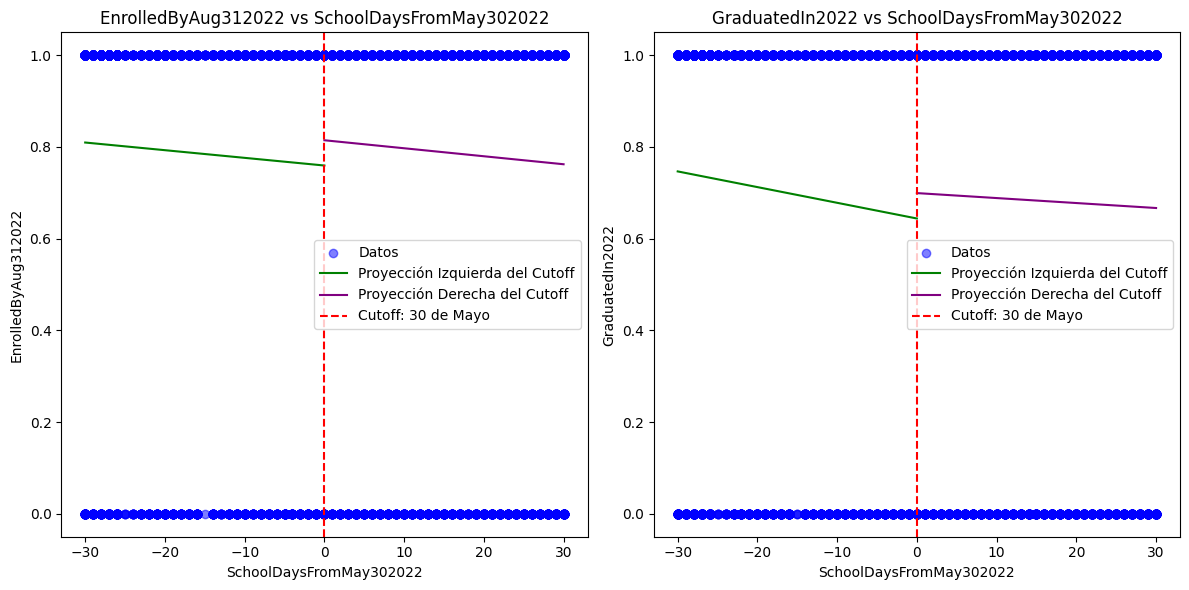

In [29]:
#p4)

# izq y der del cutoff
left_of_cutoff = datos[datos['SchoolDaysFromMay302022'] < 0]
right_of_cutoff = datos[datos['SchoolDaysFromMay302022'] >= 0]

# reg para EnrolledByAug312022
X_left = sm.add_constant(left_of_cutoff['SchoolDaysFromMay302022'])
X_right = sm.add_constant(right_of_cutoff['SchoolDaysFromMay302022'])
y_left = left_of_cutoff['EnrolledByAug312022']
y_right = right_of_cutoff['EnrolledByAug312022']

reg_left = sm.OLS(y_left, X_left).fit()
reg_right = sm.OLS(y_right, X_right).fit()

# predic
X_range_left = np.linspace(min(left_of_cutoff['SchoolDaysFromMay302022']), 0, 100)
X_range_right = np.linspace(0, max(right_of_cutoff['SchoolDaysFromMay302022']), 100)

pred_left = reg_left.predict(sm.add_constant(X_range_left))
pred_right = reg_right.predict(sm.add_constant(X_range_right))

# ajuste
y_left_graduated = left_of_cutoff['GraduatedIn2022']
y_right_graduated = right_of_cutoff['GraduatedIn2022']

reg_left_graduated = sm.OLS(y_left_graduated, X_left).fit()
reg_right_graduated = sm.OLS(y_right_graduated, X_right).fit()

# predic GraduatedIn2022
pred_left_graduated = reg_left_graduated.predict(sm.add_constant(X_range_left))
pred_right_graduated = reg_right_graduated.predict(sm.add_constant(X_range_right))

# graficos side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Gráfico 1: EnrolledByAug312022 vs SchoolDaysFromMay302022
axes[0].scatter(datos['SchoolDaysFromMay302022'], datos['EnrolledByAug312022'], color='blue', alpha=0.5, label='Datos')
axes[0].plot(X_range_left, pred_left, color='green', label='Proyección Izquierda del Cutoff')
axes[0].plot(X_range_right, pred_right, color='purple', label='Proyección Derecha del Cutoff')
axes[0].axvline(x=0, color='red', linestyle='--', label="Cutoff: 30 de Mayo")
axes[0].set_title('EnrolledByAug312022 vs SchoolDaysFromMay302022')
axes[0].set_xlabel('SchoolDaysFromMay302022')
axes[0].set_ylabel('EnrolledByAug312022')
axes[0].legend()

# Gráfico 2: GraduatedIn2022 vs SchoolDaysFromMay302022
axes[1].scatter(datos['SchoolDaysFromMay302022'], datos['GraduatedIn2022'], color='blue', alpha=0.5, label='Datos')
axes[1].plot(X_range_left, pred_left_graduated, color='green', label='Proyección Izquierda del Cutoff')
axes[1].plot(X_range_right, pred_right_graduated, color='purple', label='Proyección Derecha del Cutoff')
axes[1].axvline(x=0, color='red', linestyle='--', label="Cutoff: 30 de Mayo")
axes[1].set_title('GraduatedIn2022 vs SchoolDaysFromMay302022')
axes[1].set_xlabel('SchoolDaysFromMay302022')
axes[1].set_ylabel('GraduatedIn2022')
axes[1].legend()


plt.tight_layout()
p3_graph_path = os.path.join(output_path, 'Gráfico p3.png')
plt.savefig(p3_graph_path)
plt.show()




In [30]:
#p5
datos = pd.read_stata(os.path.join(data_path, file_name))
# var cuadratica
datos['SchoolDaysFromMay302022_squared'] = datos['SchoolDaysFromMay302022'] ** 2

dayofweek_dummies = [col for col in datos.columns if col.startswith('DayOfWeekDroppedOut_')]

if dayofweek_dummies:
    dayofweek_dummies_str = ' + ' + ' + '.join(dayofweek_dummies)
else:
    dayofweek_dummies_str = ''

formula_enrollment_quad = f'EnrolledByAug312022 ~ DroppedOutMay30Before + SchoolDaysFromMay302022 + SchoolDaysFromMay302022_squared + DroppedOutMay30Before:SchoolDaysFromMay302022 + DroppedOutMay30Before:SchoolDaysFromMay302022_squared + C(IDschool){dayofweek_dummies_str}'

modelo_enrollment_quad = smf.ols(formula_enrollment_quad, data=datos).fit()

coef_interes_enrollment_quad = ['Intercept', 'DroppedOutMay30Before', 'SchoolDaysFromMay302022', 'SchoolDaysFromMay302022_squared', 'DroppedOutMay30Before:SchoolDaysFromMay302022', 'DroppedOutMay30Before:SchoolDaysFromMay302022_squared'] + dayofweek_dummies

tabla_coeficientes_enrollment_quad = pd.DataFrame({
    'Coeficiente': modelo_enrollment_quad.params[modelo_enrollment_quad.params.index.isin(coef_interes_enrollment_quad)],
    'Error estándar': modelo_enrollment_quad.bse[modelo_enrollment_quad.bse.index.isin(coef_interes_enrollment_quad)],
    't-valor': modelo_enrollment_quad.tvalues[modelo_enrollment_quad.tvalues.index.isin(coef_interes_enrollment_quad)],
    'P-valor': modelo_enrollment_quad.pvalues[modelo_enrollment_quad.pvalues.index.isin(coef_interes_enrollment_quad)]
})


latex_path_enrollment_quad = os.path.join(output_path, 'tabla_coeficientes_enrollment_quad_pregunta_5.tex')
with open(latex_path_enrollment_quad, 'w') as f:
    f.write(tabla_coeficientes_enrollment_quad.to_latex(index=True))


txt_path_enrollment_quad = os.path.join(output_path, 'tabla_coeficientes_enrollment_quad_pregunta_5.txt')
with open(txt_path_enrollment_quad, 'w') as f:
    f.write(tabla_coeficientes_enrollment_quad.to_string(index=True))


print(tabla_coeficientes_enrollment_quad)

print(tabla_coeficientes_enrollment_quad.to_latex(index=True))



                                                    Coeficiente  \
Intercept                                              0.315606   
DroppedOutMay30Before                                  0.044026   
SchoolDaysFromMay302022                               -0.000224   
SchoolDaysFromMay302022_squared                        0.000043   
DroppedOutMay30Before:SchoolDaysFromMay302022         -0.001699   
DroppedOutMay30Before:SchoolDaysFromMay302022_s...    -0.000011   

                                                    Error estándar   t-valor  \
Intercept                                                 0.225146  1.401783   
DroppedOutMay30Before                                     0.030782  1.430235   
SchoolDaysFromMay302022                                   0.003607 -0.062091   
SchoolDaysFromMay302022_squared                           0.000109  0.391421   
DroppedOutMay30Before:SchoolDaysFromMay302022             0.004625 -0.367334   
DroppedOutMay30Before:SchoolDaysFromMay302022_s...

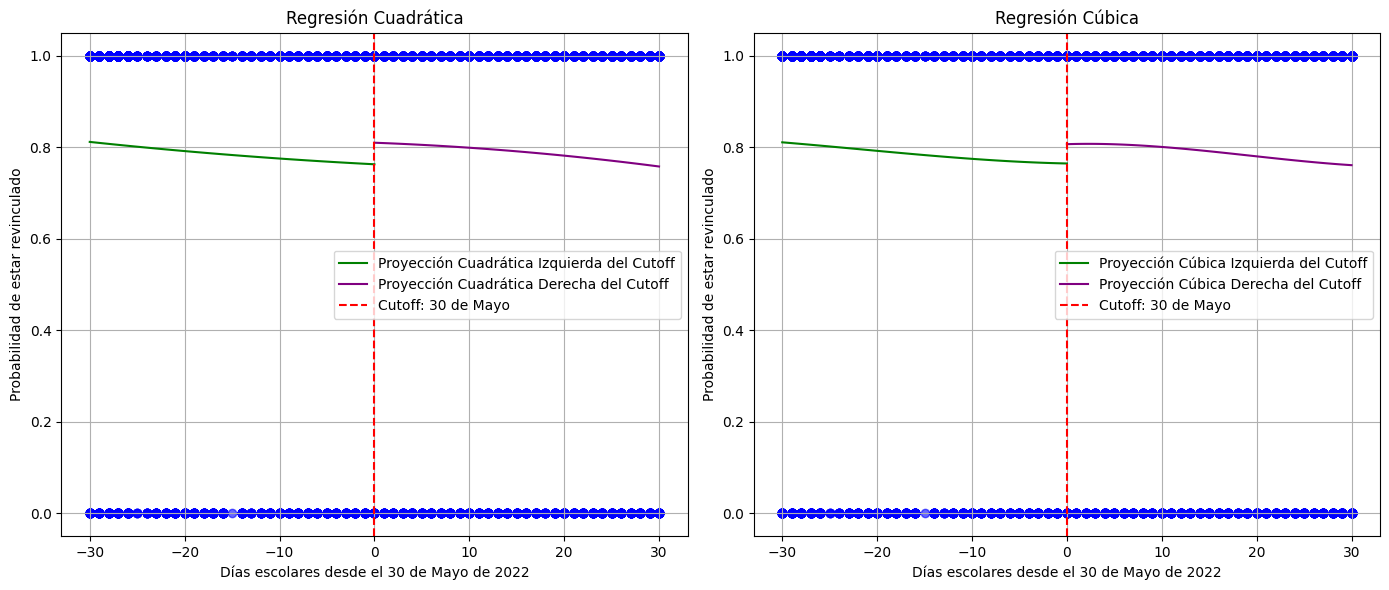

In [31]:
#p6
datos = pd.read_stata(os.path.join(data_path, file_name))
# var cubica
datos['SchoolDaysFromMay302022_squared'] = datos['SchoolDaysFromMay302022'] ** 2
datos['SchoolDaysFromMay302022_cubed'] = datos['SchoolDaysFromMay302022'] ** 3


left_of_cutoff = datos[datos['SchoolDaysFromMay302022'] < 0]
right_of_cutoff = datos[datos['SchoolDaysFromMay302022'] >= 0]

reg_left_quad = smf.ols('EnrolledByAug312022 ~ SchoolDaysFromMay302022 + SchoolDaysFromMay302022_squared', data=left_of_cutoff).fit()

reg_right_quad = smf.ols('EnrolledByAug312022 ~ SchoolDaysFromMay302022 + SchoolDaysFromMay302022_squared', data=right_of_cutoff).fit()

X_range_left = np.linspace(min(left_of_cutoff['SchoolDaysFromMay302022']), 0, 100)
X_range_right = np.linspace(0, max(right_of_cutoff['SchoolDaysFromMay302022']), 100)

pred_left_quad = reg_left_quad.predict(pd.DataFrame({
    'SchoolDaysFromMay302022': X_range_left,
    'SchoolDaysFromMay302022_squared': X_range_left ** 2
}))

pred_right_quad = reg_right_quad.predict(pd.DataFrame({
    'SchoolDaysFromMay302022': X_range_right,
    'SchoolDaysFromMay302022_squared': X_range_right ** 2
}))

#ajuste reg cubica
reg_left_cubic = smf.ols('EnrolledByAug312022 ~ SchoolDaysFromMay302022 + SchoolDaysFromMay302022_squared + SchoolDaysFromMay302022_cubed', data=left_of_cutoff).fit()
reg_right_cubic = smf.ols('EnrolledByAug312022 ~ SchoolDaysFromMay302022 + SchoolDaysFromMay302022_squared + SchoolDaysFromMay302022_cubed', data=right_of_cutoff).fit()

pred_left_cubic = reg_left_cubic.predict(pd.DataFrame({
    'SchoolDaysFromMay302022': X_range_left,
    'SchoolDaysFromMay302022_squared': X_range_left ** 2,
    'SchoolDaysFromMay302022_cubed': X_range_left ** 3
}))

pred_right_cubic = reg_right_cubic.predict(pd.DataFrame({
    'SchoolDaysFromMay302022': X_range_right,
    'SchoolDaysFromMay302022_squared': X_range_right ** 2,
    'SchoolDaysFromMay302022_cubed': X_range_right ** 3
}))

fig, axs = plt.subplots(1, 2, figsize=(14, 6))

# Gráfico de proyección cuadrática
axs[0].scatter(datos['SchoolDaysFromMay302022'], datos['EnrolledByAug312022'], color='blue', alpha=0.6)
axs[0].plot(X_range_left, pred_left_quad, color='green', label="Proyección Cuadrática Izquierda del Cutoff")
axs[0].plot(X_range_right, pred_right_quad, color='purple', label="Proyección Cuadrática Derecha del Cutoff")
axs[0].axvline(x=0, color='red', linestyle='--', label="Cutoff: 30 de Mayo")
axs[0].set_title("Regresión Cuadrática")
axs[0].set_xlabel("Días escolares desde el 30 de Mayo de 2022")
axs[0].set_ylabel("Probabilidad de estar revinculado")
axs[0].legend()
axs[0].grid(True)

# Gráfico de proyección cúbica
axs[1].scatter(datos['SchoolDaysFromMay302022'], datos['EnrolledByAug312022'], color='blue', alpha=0.6)
axs[1].plot(X_range_left, pred_left_cubic, color='green', label="Proyección Cúbica Izquierda del Cutoff")
axs[1].plot(X_range_right, pred_right_cubic, color='purple', label="Proyección Cúbica Derecha del Cutoff")
axs[1].axvline(x=0, color='red', linestyle='--', label="Cutoff: 30 de Mayo")
axs[1].set_title("Regresión Cúbica")
axs[1].set_xlabel("Días escolares desde el 30 de Mayo de 2022")
axs[1].set_ylabel("Probabilidad de estar revinculado")
axs[1].legend()
axs[1].grid(True)


plt.tight_layout()

plt_path_combined = os.path.join(output_path, 'grafico_regresion_combinada_pregunta_6.png')
plt.savefig(plt_path_combined)

plt.show()


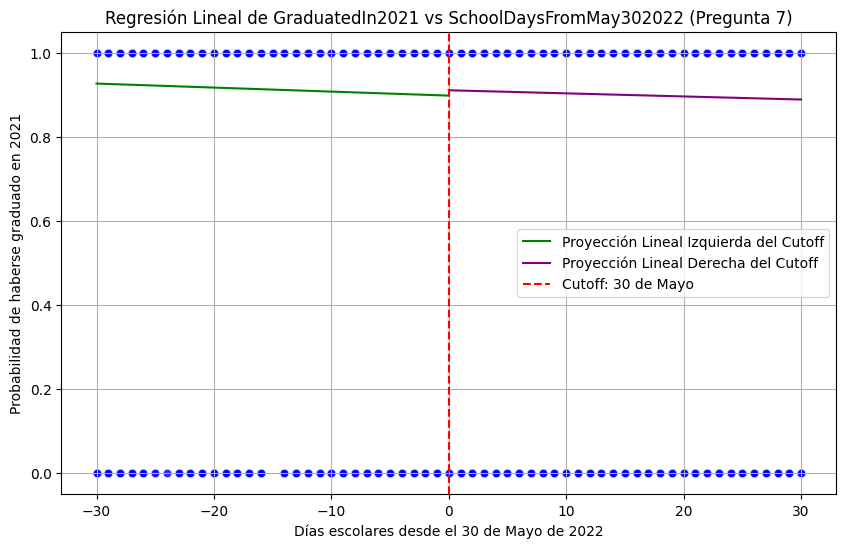

In [32]:
#p7
datos = pd.read_stata(os.path.join(data_path, file_name))
left_of_cutoff = datos[datos['SchoolDaysFromMay302022'] < 0]
right_of_cutoff = datos[datos['SchoolDaysFromMay302022'] >= 0]

reg_left_grad2021 = smf.ols('GraduatedIn2021 ~ SchoolDaysFromMay302022', data=left_of_cutoff).fit()

reg_right_grad2021 = smf.ols('GraduatedIn2021 ~ SchoolDaysFromMay302022', data=right_of_cutoff).fit()


X_range_left_grad2021 = np.linspace(min(left_of_cutoff['SchoolDaysFromMay302022']), 0, 100)
X_range_right_grad2021 = np.linspace(0, max(right_of_cutoff['SchoolDaysFromMay302022']), 100)

pred_left_grad2021 = reg_left_grad2021.predict(pd.DataFrame({
    'SchoolDaysFromMay302022': X_range_left_grad2021
}))

pred_right_grad2021 = reg_right_grad2021.predict(pd.DataFrame({
    'SchoolDaysFromMay302022': X_range_right_grad2021
}))

plt.figure(figsize=(10, 6))

sns.scatterplot(x='SchoolDaysFromMay302022', y='GraduatedIn2021', data=datos, color='blue', alpha=0.6)

plt.plot(X_range_left_grad2021, pred_left_grad2021, color='green', label="Proyección Lineal Izquierda del Cutoff")
plt.plot(X_range_right_grad2021, pred_right_grad2021, color='purple', label="Proyección Lineal Derecha del Cutoff")

plt.axvline(x=0, color='red', linestyle='--', label="Cutoff: 30 de Mayo")

plt.title("Regresión Lineal de GraduatedIn2021 vs SchoolDaysFromMay302022 (Pregunta 7)")
plt.xlabel("Días escolares desde el 30 de Mayo de 2022")
plt.ylabel("Probabilidad de haberse graduado en 2021")
plt.legend()


plt_path_grad2021_p7 = os.path.join(output_path, 'grafico_regresion_graduatedin2021_pregunta_7.png')
plt.savefig(plt_path_grad2021_p7)

plt.grid(True)
plt.show()


<ipython-input-33-2b08f2f0c368>:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  datos['GPAin2021'].fillna(gpa_mean, inplace=True)


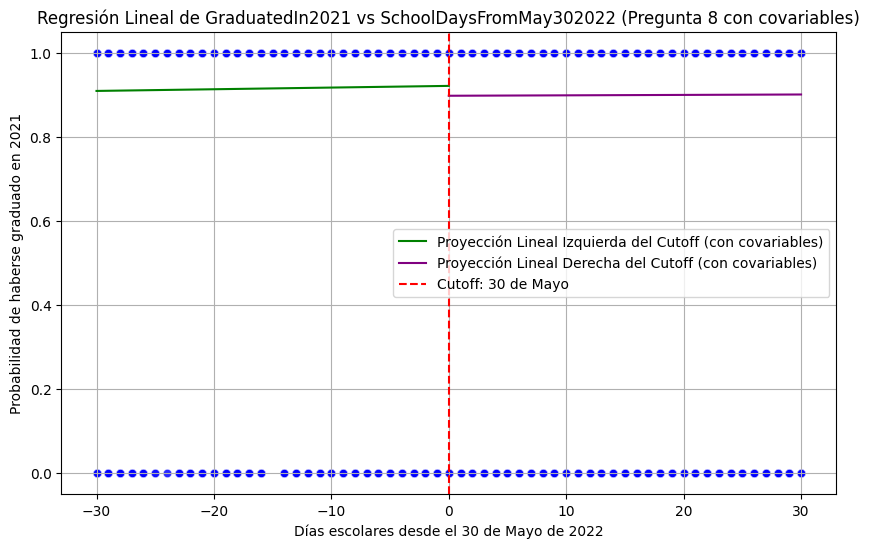

Resultados del modelo izquierdo con covariables:
                            OLS Regression Results                            
Dep. Variable:        GraduatedIn2021   R-squared:                       0.446
Model:                            OLS   Adj. R-squared:                  0.446
Method:                 Least Squares   F-statistic:                     629.5
Date:                Sat, 05 Oct 2024   Prob (F-statistic):               0.00
Time:                        00:30:47   Log-Likelihood:                 608.82
No. Observations:                3912   AIC:                            -1206.
Df Residuals:                    3906   BIC:                            -1168.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------

In [33]:
#p8
datos = pd.read_stata(os.path.join(data_path, file_name))
# Reemplazando valores NA de gpa por la media, ya que al ser tan pocos no debería cambiar estadísticamente
gpa_mean = datos['GPAin2021'].mean()
datos['GPAin2021'].fillna(gpa_mean, inplace=True)

left_of_cutoff = datos[datos['SchoolDaysFromMay302022'] < 0]
right_of_cutoff = datos[datos['SchoolDaysFromMay302022'] >= 0]
covariables = 'GPAin2021 + AttendanceIn2021 + Female + Migrant'

#izq
formula_left_grad2021_cov = f'GraduatedIn2021 ~ SchoolDaysFromMay302022 + {covariables}'
reg_left_grad2021_cov = smf.ols(formula_left_grad2021_cov, data=left_of_cutoff).fit()

#der
formula_right_grad2021_cov = f'GraduatedIn2021 ~ SchoolDaysFromMay302022 + {covariables}'
reg_right_grad2021_cov = smf.ols(formula_right_grad2021_cov, data=right_of_cutoff).fit()


X_range_left_grad2021_cov = np.linspace(min(left_of_cutoff['SchoolDaysFromMay302022']), 0, 100)
X_range_right_grad2021_cov = np.linspace(0, max(right_of_cutoff['SchoolDaysFromMay302022']), 100)

pred_left_grad2021_cov = reg_left_grad2021_cov.predict(pd.DataFrame({
    'SchoolDaysFromMay302022': X_range_left_grad2021_cov,
    'GPAin2021': np.mean(left_of_cutoff['GPAin2021']),
    'AttendanceIn2021': np.mean(left_of_cutoff['AttendanceIn2021']),
    'Female': np.mean(left_of_cutoff['Female']),
    'Migrant': np.mean(left_of_cutoff['Migrant'])
}))

pred_right_grad2021_cov = reg_right_grad2021_cov.predict(pd.DataFrame({
    'SchoolDaysFromMay302022': X_range_right_grad2021_cov,
    'GPAin2021': np.mean(right_of_cutoff['GPAin2021']),
    'AttendanceIn2021': np.mean(right_of_cutoff['AttendanceIn2021']),
    'Female': np.mean(right_of_cutoff['Female']),
    'Migrant': np.mean(right_of_cutoff['Migrant'])
}))

plt.figure(figsize=(10, 6))

sns.scatterplot(x='SchoolDaysFromMay302022', y='GraduatedIn2021', data=datos, color='blue', alpha=0.6)

plt.plot(X_range_left_grad2021_cov, pred_left_grad2021_cov, color='green', label="Proyección Lineal Izquierda del Cutoff (con covariables)")
plt.plot(X_range_right_grad2021_cov, pred_right_grad2021_cov, color='purple', label="Proyección Lineal Derecha del Cutoff (con covariables)")

plt.axvline(x=0, color='red', linestyle='--', label="Cutoff: 30 de Mayo")

plt.title("Regresión Lineal de GraduatedIn2021 vs SchoolDaysFromMay302022 (Pregunta 8 con covariables)")
plt.xlabel("Días escolares desde el 30 de Mayo de 2022")
plt.ylabel("Probabilidad de haberse graduado en 2021")
plt.legend()

plt_path_grad2021_p8 = os.path.join(output_path, 'grafico_regresion_graduatedin2021_pregunta_8.png')
plt.savefig(plt_path_grad2021_p8)

plt.grid(True)
plt.show()


print("Resultados del modelo izquierdo con covariables:")
print(reg_left_grad2021_cov.summary())

print("\nResultados del modelo derecho con covariables:")
print(reg_right_grad2021_cov.summary())


In [34]:
#p10.b

formula_first_stage = 'ListedInDropoutReport ~ DroppedOutMay30Before + SchoolDaysFromMay302022 + DroppedOutMay30Before:SchoolDaysFromMay302022 + C(IDschool) + C(DayOfWeekDroppedOut)'
modelo_first_stage = smf.ols(formula_first_stage, data=datos).fit()

# 1st stage
datos['ListedInDropoutReport_Predicted'] = modelo_first_stage.predict(datos)


formula_second_stage = 'EnrolledByAug312022 ~ ListedInDropoutReport_Predicted + SchoolDaysFromMay302022 + DroppedOutMay30Before:SchoolDaysFromMay302022 + C(IDschool) + C(DayOfWeekDroppedOut)'
modelo_second_stage = smf.ols(formula_second_stage, data=datos).fit()

coeficientes_importantes = modelo_second_stage.params[['ListedInDropoutReport_Predicted', 'SchoolDaysFromMay302022', 'DroppedOutMay30Before:SchoolDaysFromMay302022']]
print(coeficientes_importantes)

output_path = '/content/drive/My Drive/output'
with open(f'{output_path}/rd_fuzzy_10b.tex', 'w') as f:
    f.write(modelo_second_stage.summary().as_latex())


ListedInDropoutReport_Predicted                  0.141977
SchoolDaysFromMay302022                         -0.002018
DroppedOutMay30Before:SchoolDaysFromMay302022    0.001767
dtype: float64


In [35]:
latex_table = coeficientes_importantes.to_latex(index=True)
print(latex_table)

\begin{tabular}{lr}
\toprule
 & 0 \\
\midrule
ListedInDropoutReport_Predicted & 0.141977 \\
SchoolDaysFromMay302022 & -0.002018 \\
DroppedOutMay30Before:SchoolDaysFromMay302022 & 0.001767 \\
\bottomrule
\end{tabular}

